In [1]:
import rasterio
import numpy as np
import geopandas as gpd
from matplotlib import pyplot as plt

from scipy.ndimage import gaussian_filter
from rasterio.features import rasterize
from rasterio.fill import fillnodata

In [1]:
from fill_dem import fill_crevasses

fill_crevasses('test_data/dem_moulins_10cm_LV95.tif', 'test_data/moulin_mask.shp', 'dem_moulins_filled.tif', smoothing_radius=0, smoothing_iterations=5)

array([[[2676.421 , 2676.4314, 2676.4844, ..., 2664.3867, 2664.3882,
         2664.39  ],
        [2676.4243, 2676.4253, 2676.4468, ..., 2664.3845, 2664.3862,
         2664.3877],
        [2676.4248, 2676.408 , 2676.4019, ..., 2664.383 , 2664.3845,
         2664.3857],
        ...,
        [2670.9158, 2670.9165, 2670.9307, ..., 2663.6597, 2663.6638,
         2663.6711],
        [2670.9226, 2670.9233, 2670.9238, ..., 2663.6636, 2663.6743,
         2663.6711],
        [2670.9233, 2670.9236, 2670.9204, ..., 2663.6772, 2663.6848,
         2663.685 ]]], shape=(1, 2934, 3604), dtype=float32)

# Fill Moulins and crevasses in DEM

In [ ]:
def fill_crevasses(input_tif, input_shp, output_tif=None, smoothing_radius=0.0, offset=0.0, filling_max_search_distance=100.0):
    """Removes and interpolates areas from geotif indicated by shapefile.
    Afterwards, a Gaussian smoothening and a vertical offset is applied.

    Args:
        input_tif: Path to geotif. 
        input_shp: Path to crevasse mask. Polygon shapefile marking areas to be removed and filled.
        output_tif: Path to save geotif. If None, no file is saved.
        smoothing_radius: Radius for gaussian filter after filling. In pixels.
        offset: Offset added to all values.  Use negative values to lower the DEM.
    """

    # Read dem data
    with rasterio.open(input_tif) as src:
        data = src.read()  # shape: (bands, rows, cols)
        transform = src.transform
        crs = src.crs
        height = src.height
        width = src.width
        profile = src.profile.copy()
        nodata = src.nodata
        pxl_size = src.transform.a

    if nodata is not None:
        data[data == nodata] = np.nan

    # read crevasse mask
    gdf = gpd.read_file(input_shp).to_crs(crs) # read crevasse shape file and transform to the raster CRS
    mask = rasterize([(geom, 1) for geom in gdf.geometry], out_shape=(height, width), transform=transform, fill=0, dtype=np.uint8)[np.newaxis,:,:]

    # fill masked values
    data = np.where(mask, np.nan, data)
    data = fillnodata(data, mask=np.ma.masked_invalid(data), max_search_distance=filling_max_search_distance, smoothing_iterations=3)

    # smoothening
    data = gaussian_filter(data, sigma=smoothing_radius)

    # apply offset
    data = data + offset

    data = data.astype(profile["dtype"])

    # Save with identical georeferencing and metadata
    if output_tif is not None:
        with rasterio.open(output_tif, "w", **profile) as dst:
            dst.write(data)

    return data

In [ ]:
fill_crevasses(input_tif, input_shp, output_tif=None, smoothing_radius=0.0, offset=0.0, filling_max_search_distance=100.0)

c:\Users\jkolar\AppData\Local\anaconda3\envs\geo\Lib\site-packages\rasterio\fill.py:72: RuntimeWarning: invalid value encountered in cast
  return _fillnodata(image, mask, max_search_distance, smoothing_iterations)


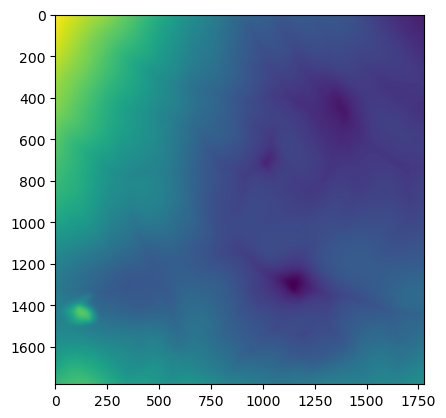

In [ ]:
input_tif = "qgis/dem_plainemorte_swissalti.tif"
input_shp = 'qgis/shp/MoulinMask.shp'
output_tif = "qgis/dem_plainemorte_swissalti_fill_minus50.tif"

data = fill_crevasses(input_tif, input_shp, output_tif=None, smoothing_radius=6, offset=-50)
plt.imshow(data[0])

c:\Users\jkolar\AppData\Local\anaconda3\envs\geo\Lib\site-packages\rasterio\fill.py:72: RuntimeWarning: invalid value encountered in cast
  return _fillnodata(image, mask, max_search_distance, smoothing_iterations)


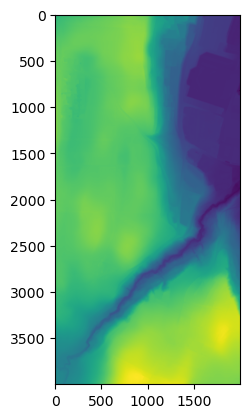

In [145]:
input_tif = "qgis/dem_aclens_swissalti.tif"
input_shp = 'qgis/shp/MoulinMask_aclens.shp'
output_tif = "qgis/dem_aclens_swissalti_fill_minus10.tif"

data = fill_crevasses(input_tif, input_shp, output_tif)
plt.imshow(data[0])

# Hole detection (exeperimental)

In [2]:
input_tif = "qgis/dem_plainemorte_swissalti.tif"
with rasterio.open(input_tif) as src:
    data = src.read()  # shape: (bands, rows, cols)
    transform = src.transform
    crs = src.crs
    height = src.height
    width = src.width
    profile = src.profile.copy()
    nodata = src.nodata
d = data[0]

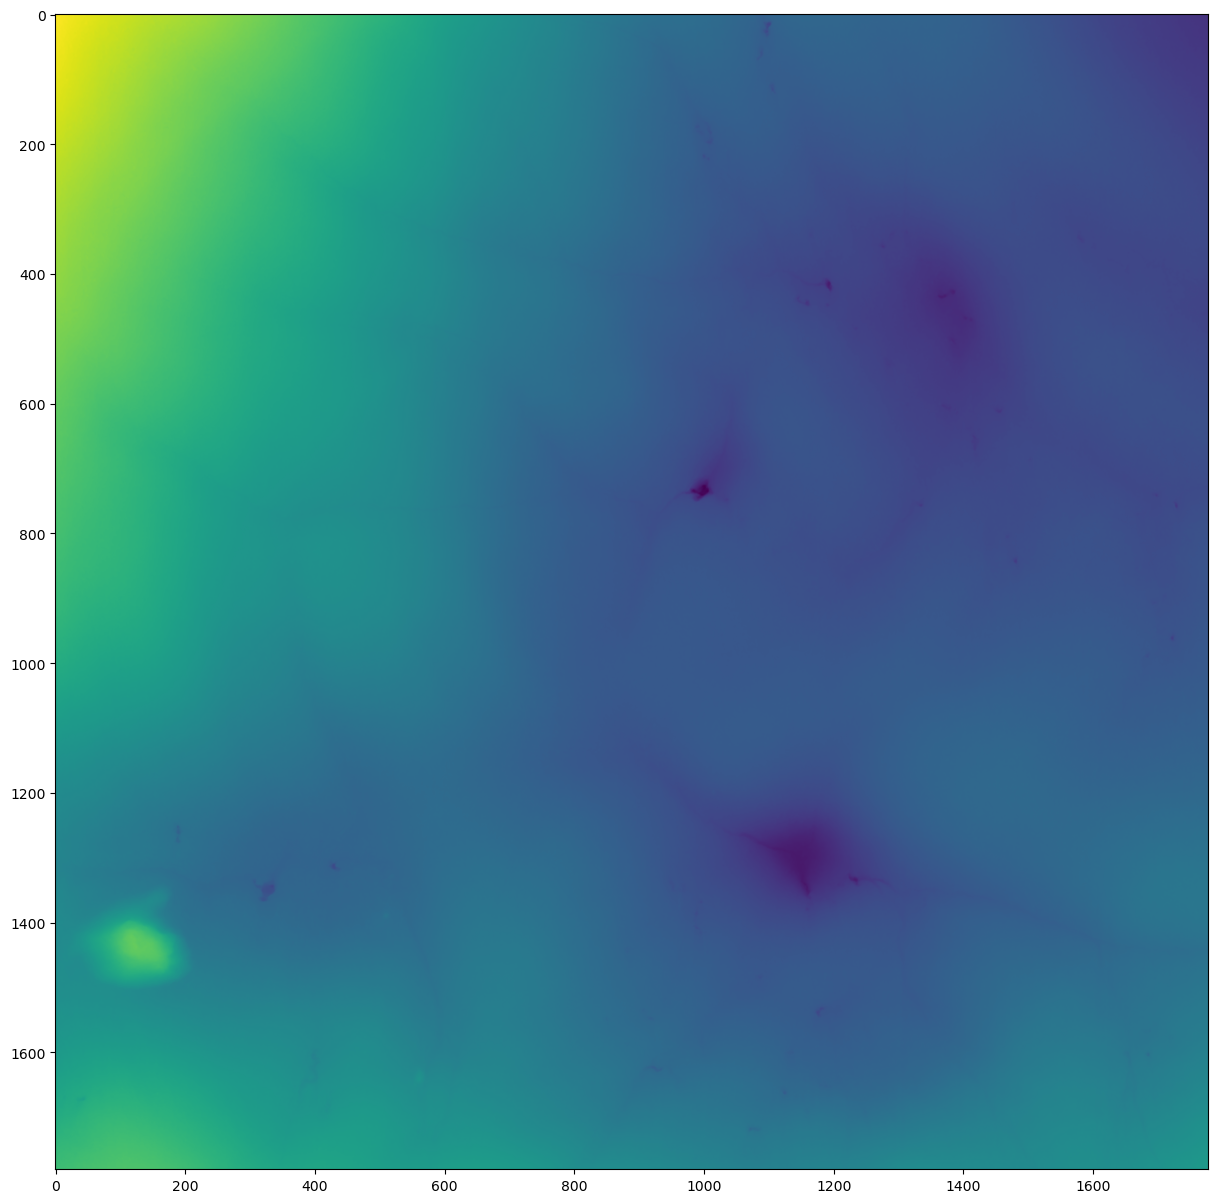

In [48]:
plt.figure(figsize=(15,15))
plt.imshow(d)

In [39]:
import numpy as np

def edge_kernel(size, thickness_rel=.15):
    thickness = int(thickness_rel * size)
    K = np.zeros((size, size), dtype=float)

    K[:thickness, :] = 1      # top
    K[-thickness:, :] = 1     # bottom
    K[:, :thickness] = 1      # left
    K[:, -thickness:] = 1     # right

    return K

kernel = edge_kernel(20)
print(kernel)

[[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1.]
 [1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1.]
 [1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1.]
 [1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1.]
 [1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1.]
 [1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1.]
 [1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1.]
 [1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1.]
 [1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1.]
 [1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1.]
 [1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1.]
 [1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1.]
 [1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.

In [42]:
edge_kernel(20).shape

(20, 20)

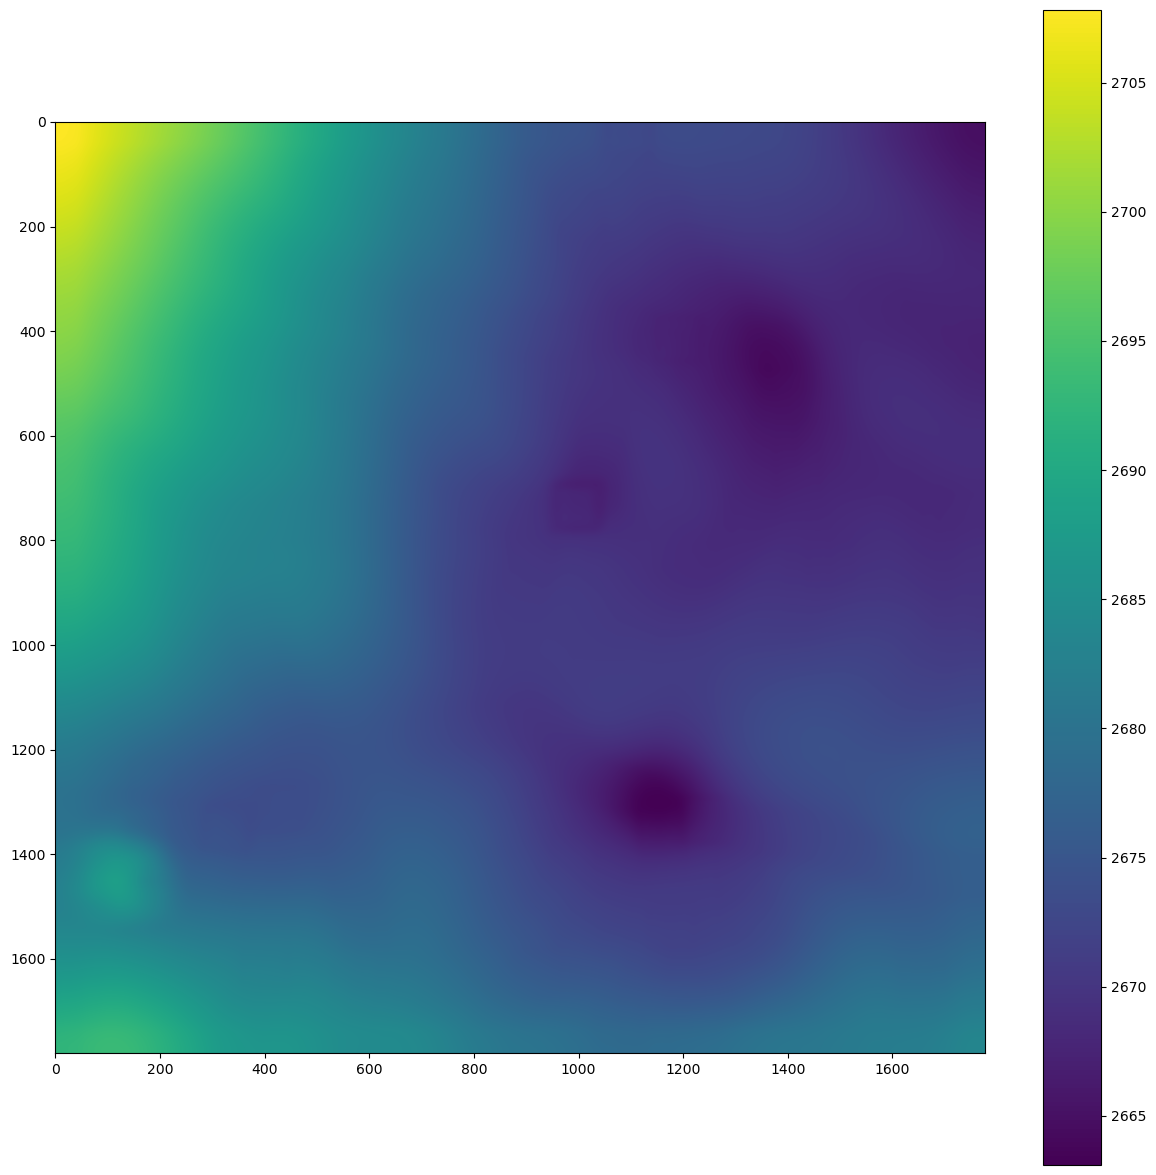

In [52]:
from scipy.signal import convolve2d
kernel = edge_kernel(100)
conv = convolve2d(d, kernel, mode='same', boundary='symm') / kernel.sum()

plt.figure(figsize=(15,15))
plt.imshow(conv)
plt.colorbar()

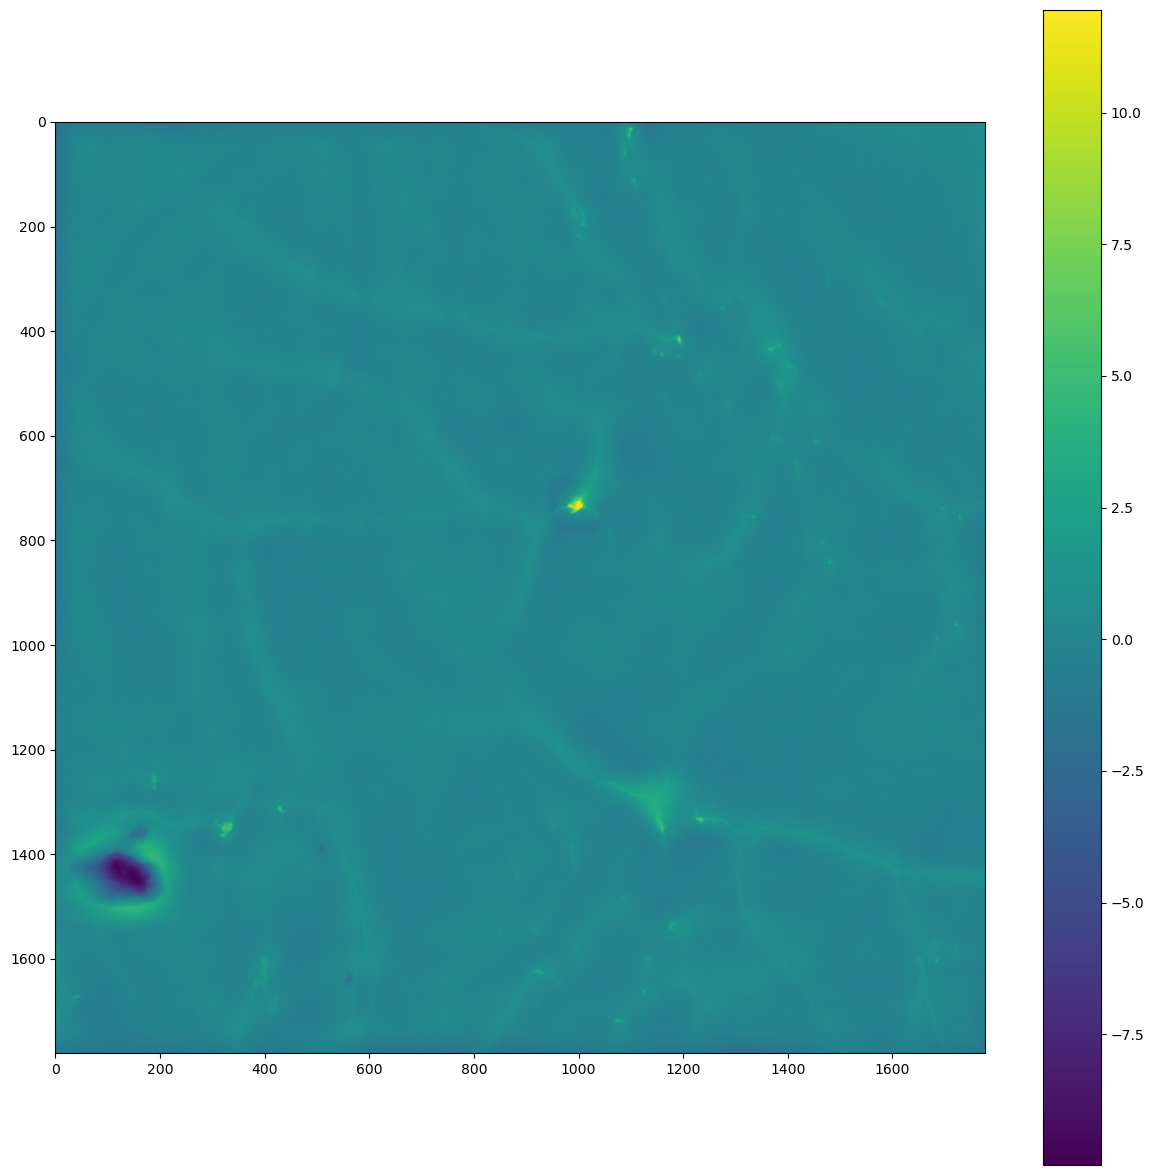

In [53]:
plt.figure(figsize=(15,15))
plt.imshow(conv - d)
plt.colorbar()

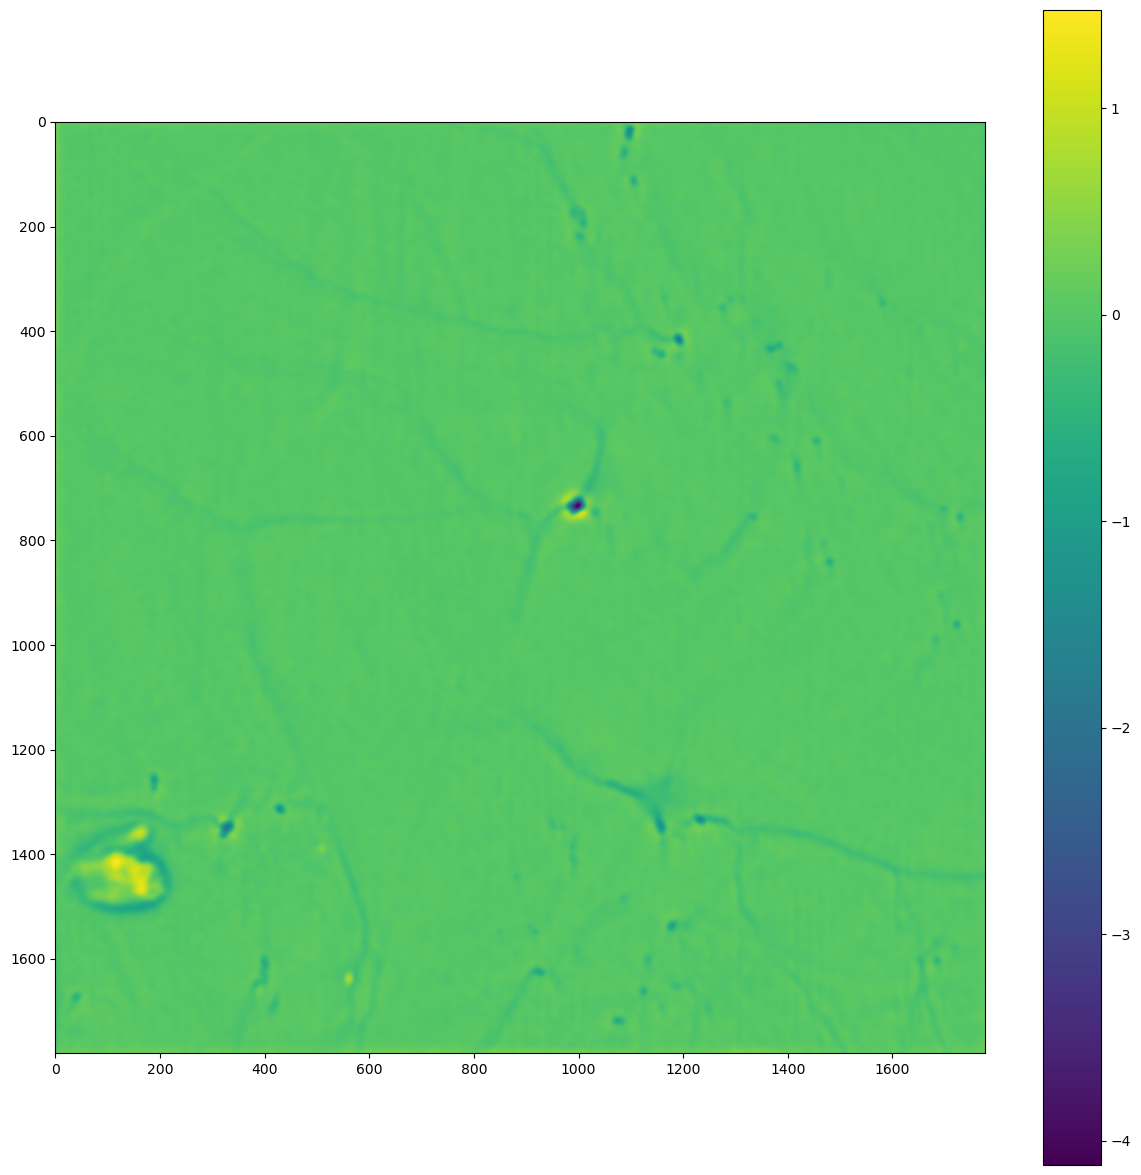

In [31]:
norm = gaussian_filter(d- gaussian_filter(d, sigma=10), sigma=5) 

plt.figure(figsize=(15,15))
plt.imshow(norm)
plt.colorbar()

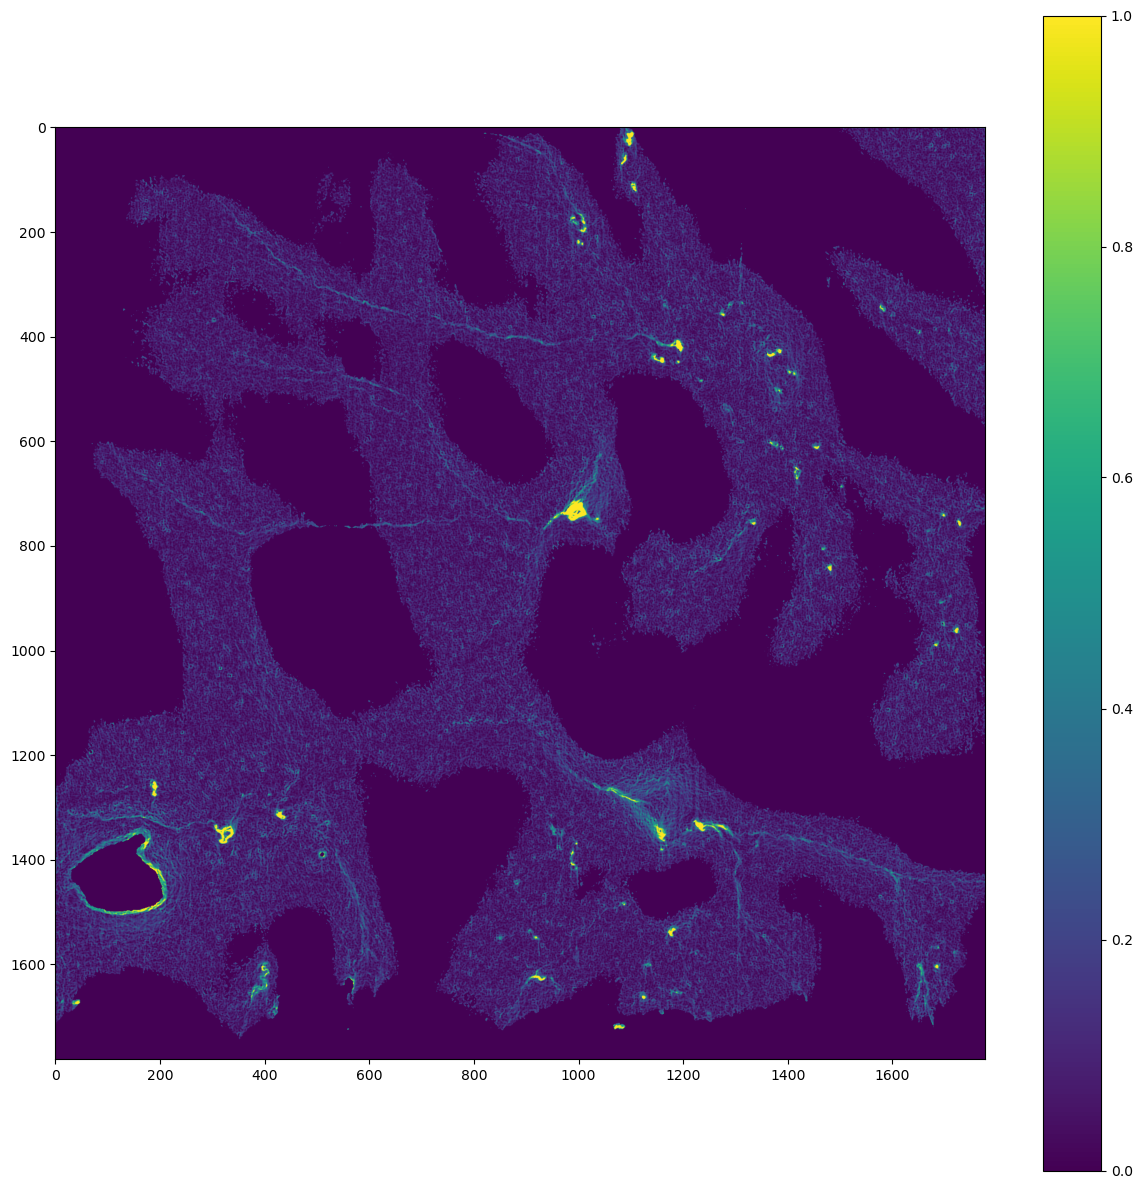

In [25]:
from scipy.ndimage import maximum_filter, minimum_filter, median_filter
filter_size = 5

norm = d - gaussian_filter(d, sigma=50)

filtered = maximum_filter(norm, size=filter_size) - norm 

filter_size = 100
low_filtered = gaussian_filter(d, sigma=filter_size) - d
filtered[low_filtered < 0] = 0

plt.figure(figsize=(15,15))

plt.imshow(filtered, vmin=0, vmax=1)
plt.colorbar()

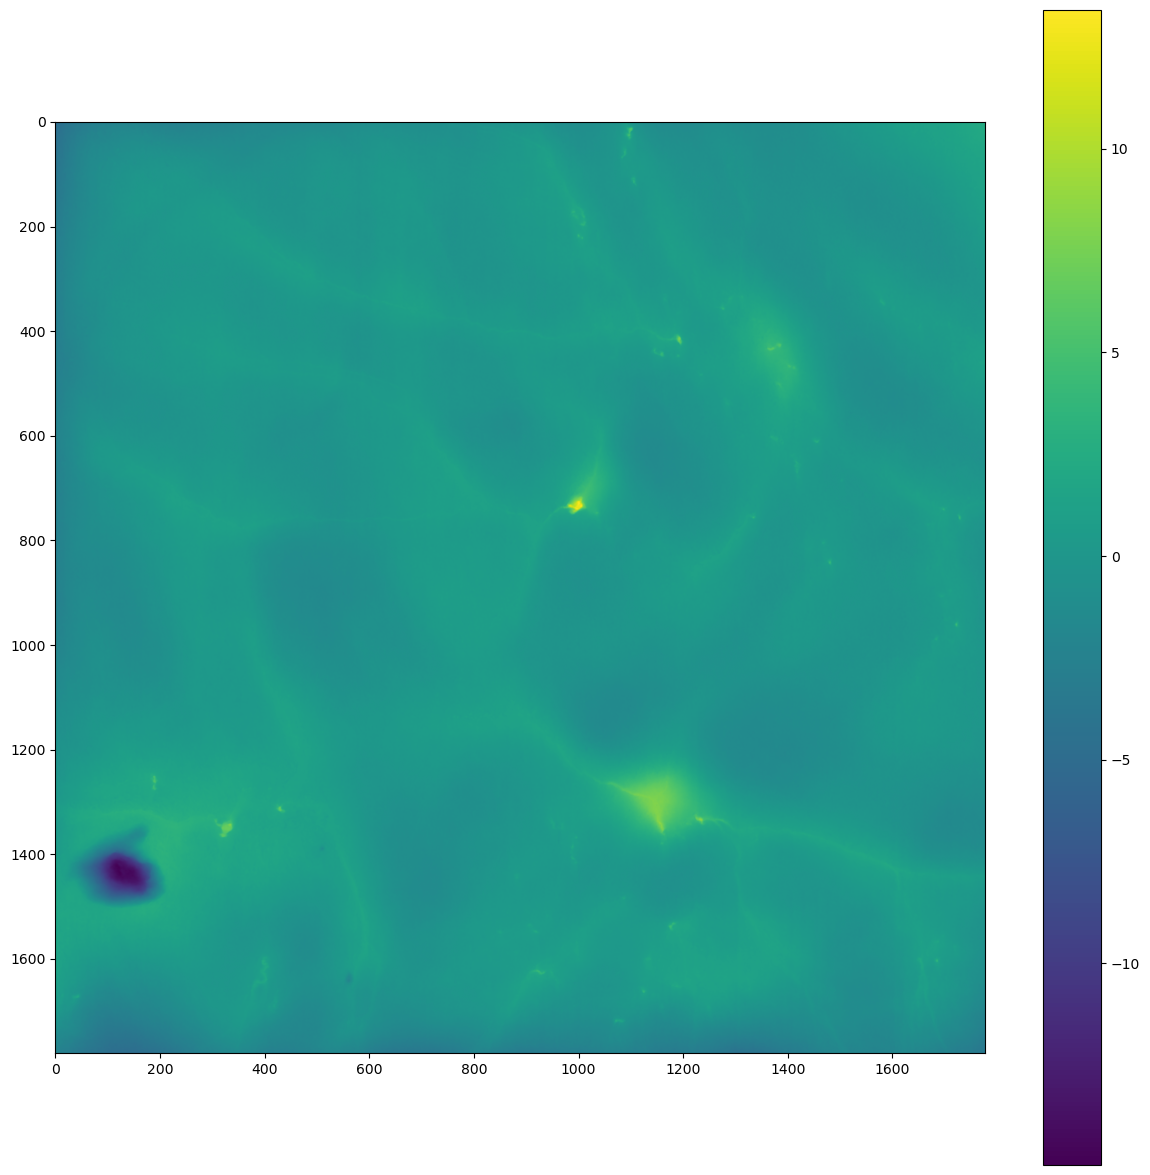

In [ ]:
filter_size = 100
filtered = gaussian_filter(d, sigma=filter_size) - d

plt.figure(figsize=(15,15))

plt.imshow(filtered)
plt.colorbar()

In [ ]:
input_tif = "qgis/dem_aclens_swissalti.tif"
input_shp = 'qgis/shp/MoulinMask_aclens.shp'
output_tif = "qgis/dem_aclens_swissalti_fill_minus10.tif"

# Read data and metadata
with rasterio.open(input_tif) as src:
    data = src.read()  # shape: (bands, rows, cols)
    transform = src.transform
    crs = src.crs
    height = src.height
    width = src.width
    profile = src.profile.copy()
    nodata = src.nodata

if nodata is not None:
    data[data == nodata] = np.nan

gdf = gpd.read_file(input_shp)

mask = rasterize(
    [(geom, 1) for geom in gdf.geometry],
    out_shape=(height, width),
    transform=transform,
    fill=0,
    dtype=np.uint8,
)[np.newaxis,:,:]

data = np.where(mask, np.nan, data)

data = fillnodata(data, mask=np.ma.masked_invalid(data), max_search_distance=100.0, smoothing_iterations=3)

# fill gaps
#data = nnFill(data)

#smoothening
pxl_size = .5
smoothing_radius = 3
data = gaussian_filter(data, sigma=smoothing_radius/pxl_size)

#apply offset
offset = -10.0
data = data + offset

# Optional: cast back to original dtype if desired
data = data.astype(profile["dtype"])

# Save with identical georeferencing and metadata
with rasterio.open(output_tif, "w", **profile) as dst:
    dst.write(data)

c:\Users\jkolar\AppData\Local\anaconda3\envs\geo\Lib\site-packages\rasterio\fill.py:72: RuntimeWarning: invalid value encountered in cast
  return _fillnodata(image, mask, max_search_distance, smoothing_iterations)


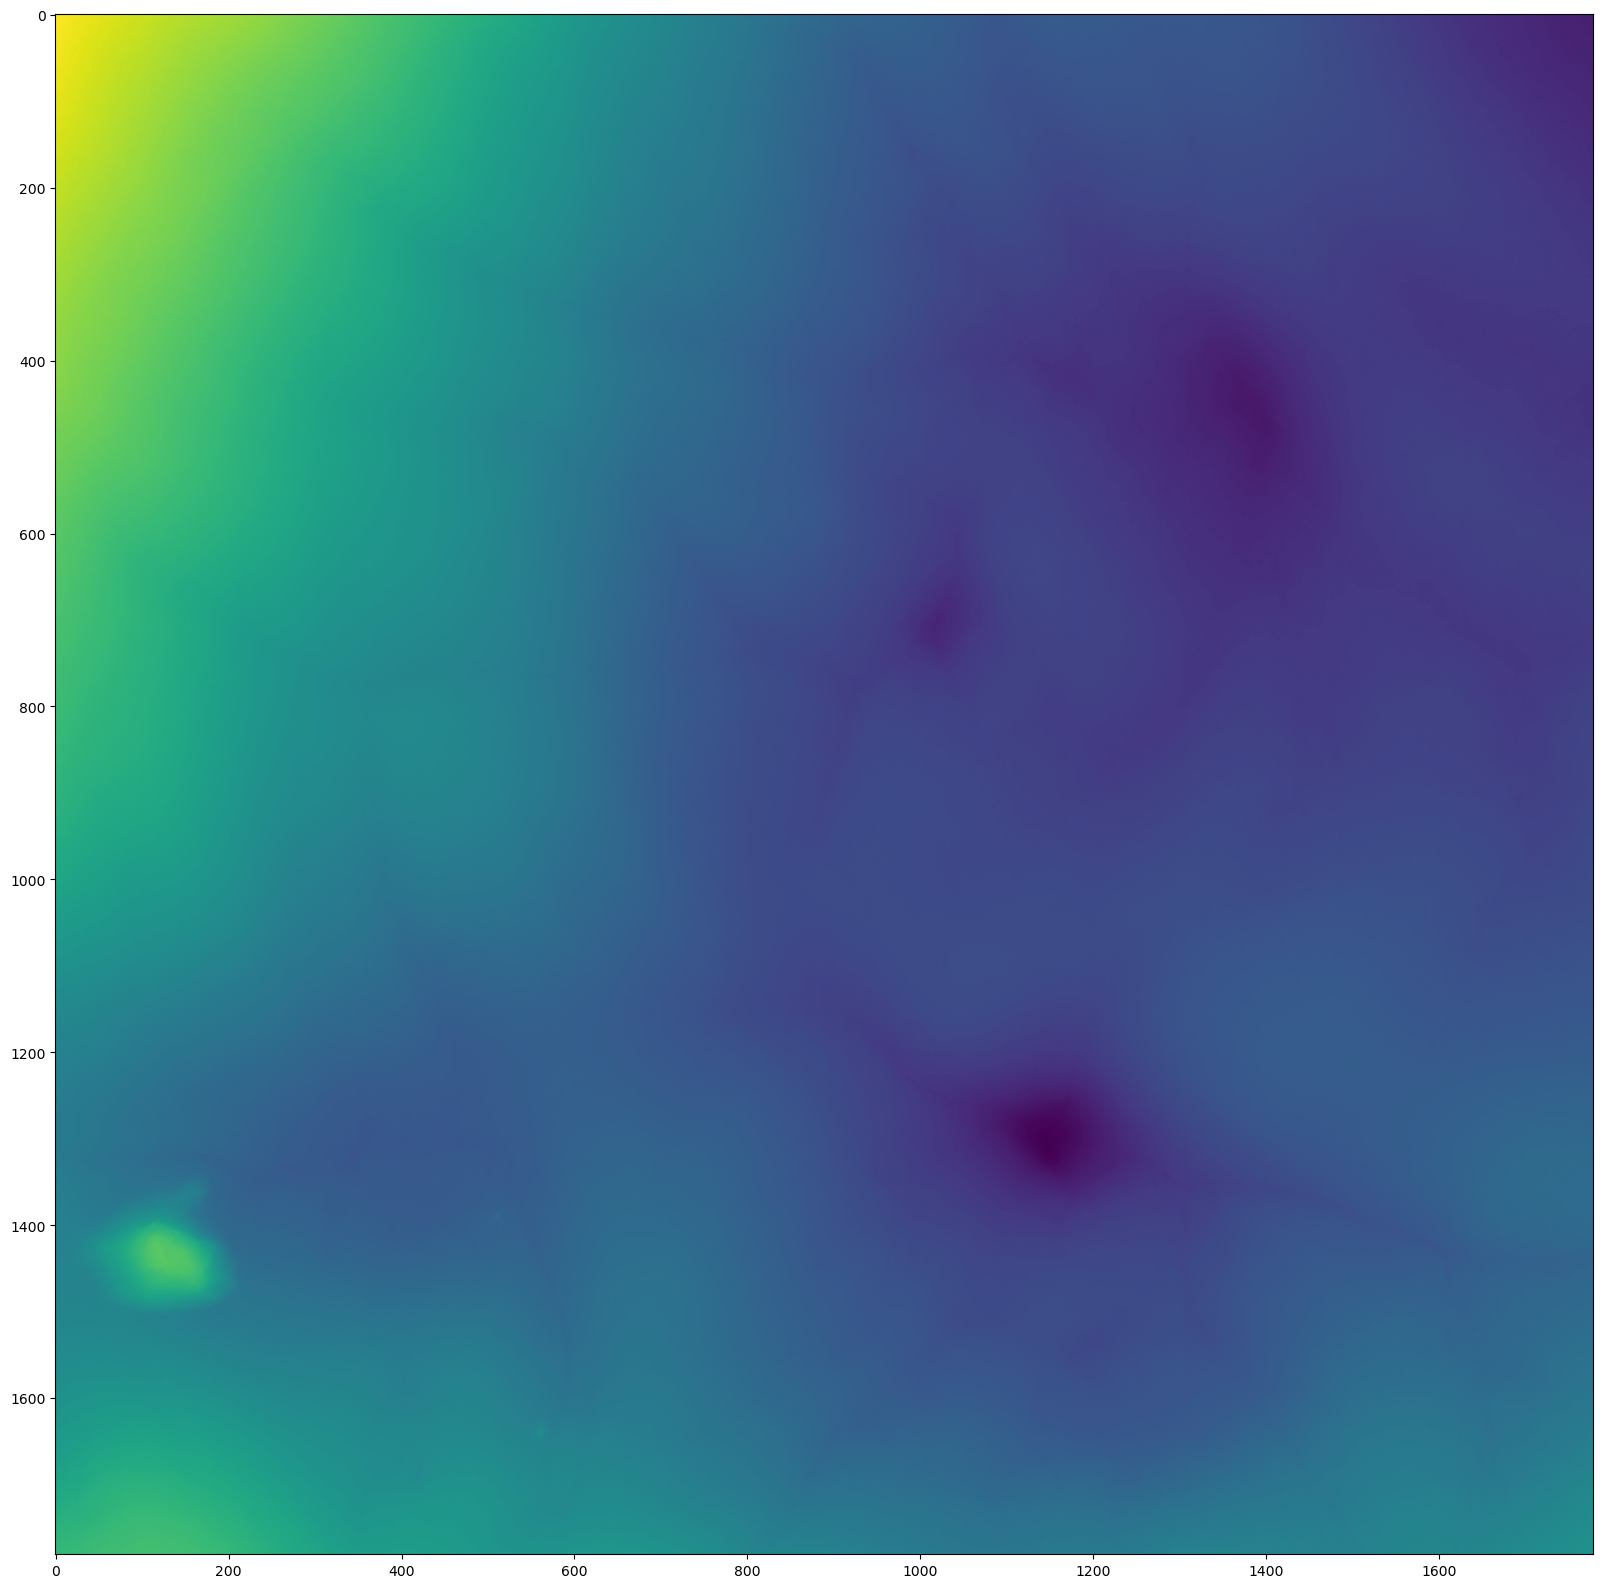

In [119]:
plt.figure(figsize=(20,20))
plt.imshow(data[0])

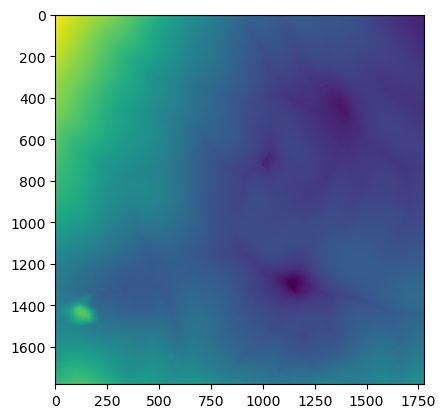

In [61]:
plt.imshow(filled[0])

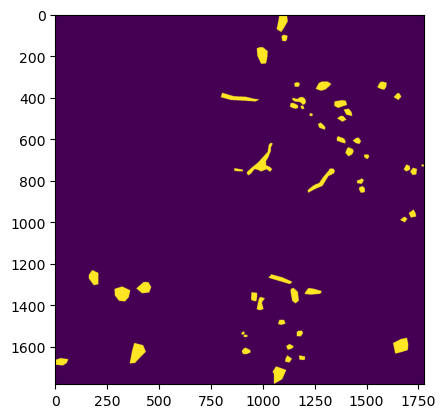

In [30]:
plt.imshow(mask)

In [41]:
data.shape, mask.shape

((1, 1781, 1778), (1, 1781, 1778))

In [49]:
mask.astype(bool)

array([[[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]]],
      shape=(1, 1781, 1778))

IndexError: index 1 is out of bounds for axis 0 with size 1

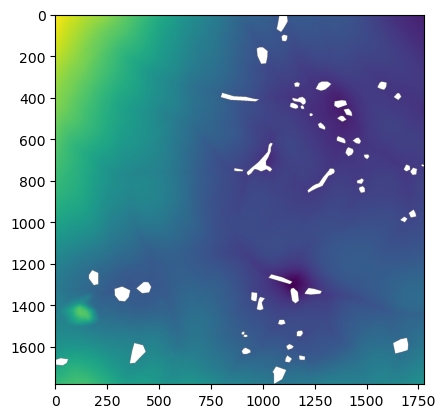

In [53]:
plt.imshow(data[0])